# Proyecto Oráculo — Notebook de búsqueda (ADAG1)

Análisis y Diseño de Algoritmos · 2026-B · Universidad de Caldas
**Grupo:** ADAG1 · **Subproyecto:** 1 · **Integrante:** Tania Botina

Este notebook documenta, de forma reproducible, cómo se obtuvo la configuración de `entrega.json`:

1. **Fase 1 — ascenso por coordenadas** (Algoritmo 2.3.2 del enunciado, dos pasadas): desde una configuración inicial aleatoria, se barre cada ranura con las demás fijas y se queda la mejor opción; entre pasadas se descartan las opciones con evidencia de daño.
2. **Poda por evidencia de trazas:** en cada ranura sobreviven las opciones competitivas; cada descarte queda justificado con aciertos y familias de restricciones que la opción rompe.
3. **Fase 2 — exhaustivo sobre el subespacio podado:** se evalúan todas las combinaciones de las candidatas.
4. **Temperatura** sobre la mejor configuración y **validación final** con `oraculo.validar`.

Solo se usa la API pública del oráculo (`evaluar`, `validar`, `espacio`, `RANURAS`, `TEMPERATURAS` y las trazas).

**Cómo ejecutarlo:** Entorno de ejecución ▸ Cambiar tipo ▸ **T4 GPU**. Corran la celda 1 y **reinicien la sesión**; después, *Ejecutar todo*. La caché vive en Drive: si Colab se desconecta, re-ejecuten todo y lo ya generado vuelve en ~0 s (el recorrido es determinista), así que se continúa donde quedó.

## 1 · Instalar y bajar los archivos del curso  ·  *al terminar, reinicien la sesión*

In [2]:
# bitsandbytes: checkpoints 4-bit (qwen8b, mistral7b). nltk/spacy/emoji/langdetect:
# los usa el verificador de open-instruct, no el notebook.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
# --no-cache: Colab a veces reusa un ayudas.py viejo y el alias no existe.
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
fatal: destination path 'open-instruct' already exists and is not an empty directory.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · Modelo y oráculo

In [1]:
import sys

import torch
import transformers

from ayudas import cargar_modelo

print("Python", sys.version.split()[0], "· torch", torch.__version__, "· transformers", transformers.__version__)

# El nombre del modelo entra en la clave de caché: cambiarlo invalida lo ya generado.
modelo = cargar_modelo("qwen17b")

Python 3.13.16 · torch 2.11.0+cu130 · transformers 5.22.1
cargando qwen17b → Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


In [2]:
from google.colab import drive

drive.mount("/content/drive")

from ayudas import cargar_datos, dividir
from oraculo import RANURAS, TEMPERATURAS, Oraculo, espacio

datos = cargar_datos()
busqueda, validacion = dividir(datos)

# lote=32 / presupuesto=64M: medido en E1, 3.0 min por evaluación frente a 3.4 con lote=16.
# Queda fijo: lotes de distinto tamaño pueden cambiar levemente las salidas en fp16.
oraculo = Oraculo(
    modelo, busqueda, validacion,
    cache="/content/drive/MyDrive/oraculo_cache.json",
    lote=32, presupuesto=64_000_000,
)

CONFIGS = espacio()
print(len(CONFIGS), "configuraciones con temperatura 0.0")

Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
caché: 8564 respuestas recuperadas
32768 configuraciones con temperatura 0.0


## 3 · Parámetros

| Parámetro | Valor | Por qué |
|---|---|---|
| `INSTANCIAS` | las 100 de `busqueda` | todas, siempre las mismas: con menos, muchas configs empatan en 0 (todo-o-nada) |
| `SEMILLA` | 2026 | fija la configuración inicial (la misma de la prueba de tiempo E0) |
| `SEMILLA_ORACULO` | 1 | semilla de generación; fija para que todo se recupere de la caché |
| `TOLERANCIA` | 2 instancias | con n = 100, diferencias de 1–2 aciertos no son evidencia (ver informe §6.1) |
| `PASADAS` (sección 4) | 2 | la pasada 1 poda opciones con evidencia de daño; la 2 re-evalúa las sobrevivientes en un contexto más limpio |
| `MAX_SUBESPACIO` | 64 | tope de la fase 2: ≈ 3.2 h de GPU a 3 min por evaluación |

Presupuesto estimado (3 min por evaluación): pasada 1 = 36 evaluaciones (≈ 1.8 h); pasada 2 = 10–30 (≈ 0.5–1.5 h); fase 2 ≤ 64 (≤ 3.2 h); temperatura 2. Si el tiempo de GPU no alcanza, bajen `MAX_SUBESPACIO` (p. ej. a 32) antes de la fase 2 y anótenlo en la bitácora.

In [3]:
import itertools
import math
import os
import random
import time
from collections import Counter

import pandas as pd

from ayudas import curva

INSTANCIAS = busqueda
SEMILLA = 2026
SEMILLA_ORACULO = 1
TOLERANCIA = 2
MAX_SUBESPACIO = 64

CARPETA = "/content/drive/MyDrive/oraculo_adag1"
os.makedirs(CARPETA, exist_ok=True)

OPCIONES = {ranura: sorted({c[ranura] for c in CONFIGS}) for ranura in RANURAS}

random.seed(SEMILLA)
INICIO = dict(random.sample(CONFIGS, 2)[0])
assert INICIO == {"rol": 1, "estrategia": 7, "formato": 1, "estilo": 7, "cierre": 6, "temperatura": 0.0}, INICIO

print("ranuras:", RANURAS)
print("opciones por ranura:", {r: len(o) for r, o in OPCIONES.items()})
print("inicio:", INICIO)

ranuras: ['rol', 'estrategia', 'formato', 'estilo', 'cierre']
opciones por ranura: {'rol': 8, 'estrategia': 8, 'formato': 8, 'estilo': 8, 'cierre': 8}
inicio: {'rol': 1, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}


### Evaluar y registrar

`medir` es la única puerta al oráculo. Cada configuración distinta se evalúa una vez y queda en `REGISTRO` (una fila por config, en el orden en que se probó), que se guarda en Drive tras cada evaluación. Una configuración repetida no se vuelve a registrar.

In [4]:
REGISTRO = []    # una fila por configuración distinta, en orden de evaluación
RESULTADOS = {}  # clave de la config -> Resultado del oráculo
historial = []   # precisión de cada config nueva, para curva(historial)


def clave(config):
    return tuple(config[r] for r in RANURAS) + (config["temperatura"],)


def aciertos(r):
    return round(r.precision * r.n)


def fallidas(r):
    """Ids de las instancias que la config no resolvió."""
    return {t["id"] for t in r.trazas}


def familia(restriccion):
    """`keywords:frequency` -> `keywords`."""
    return str(restriccion).split(":")[0]


def fallos_por_familia(r):
    """Cuántas instancias tumbó cada familia (`violo` es la primera restricción que falló)."""
    return Counter(familia(t["violo"]) for t in r.trazas)


def medir(config, fase, nota=""):
    """Evalúa `config` sobre INSTANCIAS, la registra y devuelve el Resultado.

    Lo que ya está en la caché vuelve en ~0 s: re-ejecutar el notebook tras una
    desconexión repite el mismo recorrido sin gastar GPU.
    """
    k = clave(config)
    if k in RESULTADOS:
        return RESULTADOS[k]
    t0 = time.perf_counter()
    r = oraculo.evaluar(config, INSTANCIAS, semilla=SEMILLA_ORACULO)
    dt = time.perf_counter() - t0
    RESULTADOS[k] = r
    historial.append(r.precision)
    REGISTRO.append({
        "n": len(REGISTRO) + 1,
        "fase": fase,
        **{ranura: config[ranura] for ranura in RANURAS},
        "temperatura": config["temperatura"],
        "aciertos": aciertos(r),
        "precision": r.precision,
        "segundos": round(dt, 1),
        "nota": nota,
    })
    pd.DataFrame(REGISTRO).to_csv(f"{CARPETA}/registro_evaluaciones.csv", index=False)
    print(f"[{len(REGISTRO):3d}] {fase:11s} {r.precision:6.1%}  {dt:6.1f} s  {config}")
    return r

## 4 · Fase 1 — Ascenso por coordenadas con poda entre pasadas

Para cada ranura, en el orden de `RANURAS`, se fijan las otras cuatro y se evalúan sus opciones vivas; la ranura queda con la de más aciertos. **En empate se conserva la opción actual**: no se cambia sin evidencia. (Las trazas no desempatan: `violo` es solo la primera restricción fallada, así que dos opciones con los mismos aciertos tienen el mismo total de fallos repartido entre familias.)

**Por qué dos pasadas y qué se poda entre ellas.** La evaluación es todo-o-nada: mientras las otras ranuras están "sucias", casi todas las instancias fallan igual y el beneficio de limpiar una sola ranura queda **enmascarado**. En ese contexto, una *pérdida* es evidencia (la opción daña aunque todo lo demás esté mal), pero un *empate* no lo es. Por eso:

- **Pasada 1:** se barren las 8 opciones; solo se descartan las que quedan **fuera de `TOLERANCIA`** frente a la mejor (evidencia de daño). Siempre sobreviven al menos 2.
- **Pasada 2:** se re-barren las sobrevivientes, ahora en un contexto más limpio, donde los beneficios sí se notan. Si no cambia ninguna ranura, el ascenso **convergió** (condición de parada del Algoritmo 2.3.2).

Costo: pasada 1, $1 + m\,(K-1) = 36$ evaluaciones; pasada 2, $\sum_j(\lvert\text{vivas}_j\rvert - 1)$; menos lo que ya esté en caché.

In [5]:
PASADAS = 2

actual = dict(INICIO)
medir(actual, "inicio", "config inicial (E0)")

VIVAS = {r: list(OPCIONES[r]) for r in RANURAS}  # opciones sin evidencia de daño
DESCARTES_PREVIOS = []                           # descartadas entre pasadas, con su evidencia
BARRIDOS = {}  # ranura -> (contexto, {opcion: Resultado}) de la última pasada

for p in range(1, PASADAS + 1):
    cambios = 0
    for ranura in RANURAS:
        contexto = dict(actual)
        barrido = {o: medir(dict(contexto, **{ranura: o}), f"fase1-p{p}", f"barrido {ranura}") for o in VIVAS[ranura]}
        mejor_o = max(barrido, key=lambda o: (aciertos(barrido[o]), o == contexto[ranura], -o))
        BARRIDOS[ranura] = (contexto, barrido)
        cambios += mejor_o != contexto[ranura]
        actual[ranura] = mejor_o
        print(f"--> p{p} {ranura}: {contexto[ranura]} -> {mejor_o}  "
              f"({aciertos(barrido[contexto[ranura]])} -> {aciertos(barrido[mejor_o])} aciertos)")

        if p < PASADAS:
            tope = aciertos(barrido[mejor_o])
            orden = sorted(barrido, key=lambda o: (-aciertos(barrido[o]), o != mejor_o, o))
            vivas = [o for o in orden if aciertos(barrido[o]) >= tope - TOLERANCIA] or orden[:1]
            vivas = vivas if len(vivas) >= 2 else orden[:2]
            fam_mejor = fallos_por_familia(barrido[mejor_o])
            for o in orden:
                if o not in vivas:
                    exceso = fallos_por_familia(barrido[o]) - fam_mejor
                    DESCARTES_PREVIOS.append({
                        "ranura": ranura, "opcion": o, "motivo": f"fuera de tolerancia (pasada {p})",
                        "aciertos": aciertos(barrido[o]), "mejor": f"{mejor_o} ({tope})",
                        "falla más en": ", ".join(f"{f} (+{k})" for f, k in exceso.most_common(3)) or "—",
                    })
            VIVAS[ranura] = sorted(vivas)
    print(f"pasada {p}: {cambios} ranura(s) cambiaron; vivas: {VIVAS}")
    print()
    if p > 1 and cambios == 0:
        print("convergió: la pasada no mejoró ninguna ranura")
        break

FIN_FASE1 = dict(actual)
print("fin de la fase 1:", FIN_FASE1, f"{RESULTADOS[clave(FIN_FASE1)].precision:.1%}")

[  1] inicio        8.0%     0.0 s  {'rol': 1, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  2] fase1-p1      7.0%     0.0 s  {'rol': 0, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  3] fase1-p1      4.0%     0.0 s  {'rol': 2, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  4] fase1-p1      7.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  5] fase1-p1      7.0%     0.0 s  {'rol': 4, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  6] fase1-p1      5.0%     0.0 s  {'rol': 5, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  7] fase1-p1      5.0%     0.0 s  {'rol': 6, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
[  8] fase1-p1      3.0%     0.0 s  {'rol': 7, 'estrategia': 7, 'formato': 1, 'estilo': 7, 'cierre': 6, 'temperatura': 0.0}
--> p1 r

## 5 · Análisis de fallos por ranura

Para cada ranura, una fila por opción del **último barrido** (las descartadas en la pasada 1 aparecen en la tabla de poda), con el resto de la configuración fijo tal como estaba al barrerla:

- `aciertos` y `brecha` frente a la mejor opción de la ranura;
- `pierde` / `gana`: instancias que la mejor resuelve y esta no, y al revés (comparación pareada sobre las mismas instancias);
- una columna por **familia** de restricciones: cuántas instancias tumbó (primera restricción fallada).

Las familias cuyos conteos cambian mucho de una opción a otra son las que **dependen de esa ranura**: esa es la evidencia que usa la poda.

In [6]:
def ranking(ranura):
    """Opciones de la ranura de mejor a peor; en empate, primero la elegida en la fase 1."""
    _, barrido = BARRIDOS[ranura]
    elegida = FIN_FASE1[ranura]
    return sorted(barrido, key=lambda o: (-aciertos(barrido[o]), o != elegida, o))


def tabla_ranura(ranura):
    contexto, barrido = BARRIDOS[ranura]
    mejor = ranking(ranura)[0]
    resueltas_mejor = {x["id"] for x in INSTANCIAS} - fallidas(barrido[mejor])
    filas = []
    for o in ranking(ranura):
        r = barrido[o]
        resueltas = {x["id"] for x in INSTANCIAS} - fallidas(r)
        filas.append({
            "opcion": o,
            "aciertos": aciertos(r),
            "brecha": aciertos(barrido[mejor]) - aciertos(r),
            "pierde": len(resueltas_mejor - resueltas),
            "gana": len(resueltas - resueltas_mejor),
            **fallos_por_familia(r),
        })
    return pd.DataFrame(filas).set_index("opcion").fillna(0).astype(int)


for ranura in RANURAS:
    contexto, _ = BARRIDOS[ranura]
    print(f"=== {ranura}  (contexto: { {k: v for k, v in contexto.items() if k != ranura} })")
    display(tabla_ranura(ranura))

=== rol  (contexto: {'estrategia': 7, 'formato': 3, 'estilo': 1, 'cierre': 3, 'temperatura': 0.0})


,aciertos,brecha,pierde,gana,letters,punctuation,last_word,length_constraints,copy,detectable_format,change_case,keywords,first_word,language,new,startend,combination,paragraphs,detectable_content
opcion,,,,,,,,,,,,,,,,,,,
3,14,0,0,0,2,3,10,3,12,13,9,16,6,3,5,2,1,1,0
0,13,1,5,4,2,9,10,3,11,13,4,15,6,3,5,2,2,1,1
1,13,1,7,6,2,4,11,4,12,12,3,18,5,3,5,3,2,3,0
4,12,2,4,2,2,5,10,3,12,17,5,16,6,2,5,3,1,1,0


=== estrategia  (contexto: {'rol': 3, 'formato': 3, 'estilo': 1, 'cierre': 3, 'temperatura': 0.0})


,aciertos,brecha,pierde,gana,letters,punctuation,last_word,length_constraints,copy,detectable_format,change_case,keywords,first_word,language,new,startend,combination,paragraphs,detectable_content
opcion,,,,,,,,,,,,,,,,,,,
7,14,0,0,0,2,3,10,3,12,13,9,16,6,3,5,2,1,1,0
5,11,3,6,3,2,5,10,4,11,16,6,14,5,3,5,4,1,2,1


=== formato  (contexto: {'rol': 3, 'estrategia': 7, 'estilo': 1, 'cierre': 3, 'temperatura': 0.0})


,aciertos,brecha,pierde,gana,letters,punctuation,last_word,length_constraints,copy,detectable_format,change_case,keywords,first_word,language,new,startend,combination,paragraphs,detectable_content
opcion,,,,,,,,,,,,,,,,,,,
3,14,0,0,0,2,3,10,3,12,13,9,16,6,3,5,2,1,1,0
0,14,0,5,5,3,3,9,4,11,12,8,14,8,2,5,4,1,1,1


=== estilo  (contexto: {'rol': 3, 'estrategia': 7, 'formato': 3, 'cierre': 3, 'temperatura': 0.0})


,aciertos,brecha,pierde,gana,letters,punctuation,last_word,length_constraints,copy,detectable_format,change_case,keywords,first_word,language,new,startend,combination,paragraphs
opcion,,,,,,,,,,,,,,,,,,
1,14,0,0,0,2,3,10,3,12,13,9,16,6,3,5,2,1,1
2,14,0,2,2,2,5,8,3,12,12,10,15,7,1,5,4,1,1
5,14,0,4,4,2,5,11,3,12,13,9,15,6,2,5,2,1,0
0,13,1,3,2,2,5,8,3,12,14,12,15,5,2,5,2,1,1
6,11,3,4,1,2,6,8,3,12,12,12,16,8,1,5,1,1,2
7,11,3,5,2,2,4,11,4,12,13,11,16,5,2,5,2,1,1


=== cierre  (contexto: {'rol': 3, 'estrategia': 7, 'formato': 3, 'estilo': 1, 'temperatura': 0.0})


,aciertos,brecha,pierde,gana,letters,punctuation,last_word,length_constraints,copy,detectable_format,change_case,keywords,first_word,language,new,startend,combination,paragraphs,detectable_content
opcion,,,,,,,,,,,,,,,,,,,
3,14,0,0,0,2,3,10,3,12,13,9,16,6,3,5,2,1,1,0
6,10,4,5,1,3,4,9,4,11,13,11,14,7,2,5,5,1,0,1


## 6 · Poda

Regla (fija antes de ver los resultados), aplicada al último barrido de cada ranura (las descartadas entre pasadas ya quedaron fuera):

1. Las opciones de cada ranura se ordenan por aciertos; en empate va primero la elegida en la fase 1 (así la config de la fase 1 siempre queda en el subespacio).
2. Sobreviven las **2 primeras** y además toda opción a **`TOLERANCIA` aciertos o menos** de la mejor.
3. Si el producto de candidatas supera `MAX_SUBESPACIO`, se quita la peor candidata —mayor brecha; en empate, de la ranura con más candidatas— entre las ranuras con más de 2, hasta caber.

Cada opción descartada queda con su motivo: `fuera de tolerancia`, `tope del subespacio` o `tope del subespacio (empate sin evidencia)` cuando tenía los mismos aciertos que la mejor; en ese caso el corte es arbitrario y así se reporta. La poda es **empírica** —evidencia de las trazas sobre estas 100 instancias—, no una cota demostrada como la del backtracking del enunciado (§2.3.1): una opción descartada podría rendir mejor en otro contexto.

In [7]:
def podar():
    candidatas, brecha, tolerables = {}, {}, {}
    for ranura, (_, barrido) in BARRIDOS.items():
        orden = ranking(ranura)
        tope = aciertos(barrido[orden[0]])
        conservar = [o for o in orden if aciertos(barrido[o]) >= tope - TOLERANCIA]
        candidatas[ranura] = conservar if len(conservar) >= 2 else orden[:2]
        tolerables[ranura] = set(candidatas[ranura])
        brecha.update({(ranura, o): tope - aciertos(barrido[o]) for o in barrido})

    while math.prod(len(c) for c in candidatas.values()) > MAX_SUBESPACIO:
        ranura, o = max(
            ((r, c[-1]) for r, c in candidatas.items() if len(c) > 2),
            key=lambda ro: (brecha[ro], len(candidatas[ro[0]]), -RANURAS.index(ro[0])),
        )
        candidatas[ranura].remove(o)
    return candidatas, tolerables


CANDIDATAS, TOLERABLES = podar()
assert all(FIN_FASE1[r] in CANDIDATAS[r] for r in RANURAS), "la config de la fase 1 debe quedar en el subespacio"

filas = list(DESCARTES_PREVIOS)
for ranura, (_, barrido) in BARRIDOS.items():
    mejor = CANDIDATAS[ranura][0]
    fam_mejor = fallos_por_familia(barrido[mejor])
    for o in ranking(ranura):
        if o in CANDIDATAS[ranura]:
            continue
        exceso = fallos_por_familia(barrido[o]) - fam_mejor
        if o not in TOLERABLES[ranura]:
            motivo = "fuera de tolerancia"
        elif aciertos(barrido[o]) == aciertos(barrido[mejor]):
            motivo = "tope del subespacio (empate sin evidencia)"
        else:
            motivo = "tope del subespacio"
        filas.append({
            "ranura": ranura,
            "opcion": o,
            "motivo": motivo,
            "aciertos": aciertos(barrido[o]),
            "mejor": f"{mejor} ({aciertos(barrido[mejor])})",
            "falla más en": ", ".join(f"{f} (+{k})" for f, k in exceso.most_common(3)) or "—",
        })
PODA = pd.DataFrame(filas).sort_values(["ranura", "aciertos"], ascending=[True, False], key=lambda s: s.map(RANURAS.index) if s.name == "ranura" else s)
PODA.to_csv(f"{CARPETA}/poda.csv", index=False)

print("candidatas:", CANDIDATAS)
print("tamaño del subespacio:", math.prod(len(c) for c in CANDIDATAS.values()))
display(PODA)

candidatas: {'rol': [3, 0], 'estrategia': [7, 5], 'formato': [3, 0], 'estilo': [1, 2, 5], 'cierre': [3, 6]}
tamaño del subespacio: 48


,ranura,opcion,motivo,aciertos,mejor,falla más en
24,rol,1,tope del subespacio,13,3 (14),"keywords (+2), paragraphs (+2), punctuation (+1)"
25,rol,4,tope del subespacio,12,3 (14),"detectable_format (+4), punctuation (+2), star..."
0,rol,5,fuera de tolerancia (pasada 1),5,1 (8),"startend (+2), length_constraints (+1), combin..."
1,rol,6,fuera de tolerancia (pasada 1),5,1 (8),"startend (+1), length_constraints (+1), detect..."
2,rol,2,fuera de tolerancia (pasada 1),4,1 (8),"paragraphs (+2), keywords (+2), detectable_for..."
3,rol,7,fuera de tolerancia (pasada 1),3,1 (8),"startend (+3), length_constraints (+2), keywor..."
4,estrategia,0,fuera de tolerancia (pasada 1),5,7 (8),"startend (+3), length_constraints (+1), first_..."
5,estrategia,2,fuera de tolerancia (pasada 1),5,7 (8),"paragraphs (+3), startend (+3), first_word (+2)"
6,estrategia,4,fuera de tolerancia (pasada 1),5,7 (8),"startend (+3), keywords (+2), first_word (+2)"
7,estrategia,6,fuera de tolerancia (pasada 1),5,7 (8),"paragraphs (+4), startend (+1), last_word (+1)"


**Lectura de la poda (corrida del 30 oct 2026).**

- **Pasada 1:** se descartaron **24 de 40** opciones por estar 3 o más aciertos por debajo de la mejor de su ranura. Solo `formato` (1→3), `estilo` (7→1) y `cierre` (6→3) mejoraron; en `rol` y `estrategia` ninguna opción superó a la inicial. Gracias a este descarte, la pasada 2 costó 11 evaluaciones en vez de 35.
- **Qué mostraron las trazas:** las opciones descartadas de `rol` y `estrategia` fallan más en `startend`, `length_constraints` y `paragraphs` (inicio y largo de la respuesta); las de `formato` en `change_case` y `detectable_format`; las de `estilo` y `cierre` en `change_case`, `punctuation` y `detectable_format`. Es consistente con que cada ranura dañe una parte distinta de la respuesta, y es lo que justifica cada descarte (columna `falla más en`).
- **Pasada 2:** en el contexto más limpio, `rol` cambió 1→3 (13→14 aciertos), un beneficio que en la pasada 1 estaba enmascarado. `estilo` 6 y 7 quedaron fuera de tolerancia.
- **Tope del subespacio:** `rol` 1 y 4 y `estilo` 0 quedaron dentro de tolerancia, pero se cortaron para no superar 64 configuraciones (tenían 1–2 aciertos menos que la mejor; ninguno fue un empate).
- `estrategia` 5 (−3) y `cierre` 6 (−4) siguen por la regla de "al menos 2 por ranura".

Resultado: **48 configuraciones** en el subespacio (de 32 768), 7 de ellas ya evaluadas.


## 7 · Fase 2 — Exhaustivo sobre el subespacio podado

Se evalúan todas las combinaciones de `CANDIDATAS`. Dentro del subespacio el resultado es el **óptimo exacto sobre el lote de búsqueda**; fuera de él depende de que la poda haya sido correcta.

In [8]:
SUBESPACIO = [
    dict(zip(RANURAS, combo), temperatura=0.0)
    for combo in itertools.product(*(CANDIDATAS[r] for r in RANURAS))
]
print(len(SUBESPACIO), "configuraciones;", sum(clave(c) not in RESULTADOS for c in SUBESPACIO), "sin evaluar aún")

for c in SUBESPACIO:
    medir(c, "fase2")

48 configuraciones; 41 sin evaluar aún
[ 48] fase2         9.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 3, 'estilo': 2, 'cierre': 6, 'temperatura': 0.0}
[ 49] fase2        10.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 3, 'estilo': 5, 'cierre': 6, 'temperatura': 0.0}
[ 50] fase2         9.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 0, 'estilo': 1, 'cierre': 6, 'temperatura': 0.0}
[ 51] fase2        15.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 0, 'estilo': 2, 'cierre': 3, 'temperatura': 0.0}
[ 52] fase2        12.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 0, 'estilo': 2, 'cierre': 6, 'temperatura': 0.0}
[ 53] fase2        14.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 0, 'estilo': 5, 'cierre': 3, 'temperatura': 0.0}
[ 54] fase2         7.0%     0.0 s  {'rol': 3, 'estrategia': 7, 'formato': 0, 'estilo': 5, 'cierre': 6, 'temperatura': 0.0}
[ 55] fase2        10.0%     0.0 s  {'rol': 3, 'estrategia': 5, 'formato': 3, 'estilo': 1, 'c

evaluando:   0%|          | 0/36 [00:00<?, ?inst/s]

[ 85] fase2        17.0%    95.7 s  {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 2, 'cierre': 3, 'temperatura': 0.0}


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 86] fase2         8.0%   164.6 s  {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 2, 'cierre': 6, 'temperatura': 0.0}


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 87] fase2        13.0%   174.5 s  {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 5, 'cierre': 3, 'temperatura': 0.0}


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 88] fase2         7.0%   168.1 s  {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 5, 'cierre': 6, 'temperatura': 0.0}


## 8 · Mejor configuración observada y temperatura

Se toma la de más aciertos entre **todas** las configuraciones evaluadas (temperatura 0.0). En empate gana la primera evaluada, y se listan las empatadas. Luego se prueban las otras temperaturas sobre esa configuración: como con temperatura > 0 la salida es muestreada (una sola semilla), solo se adopta si mejora **más que `TOLERANCIA`**.

In [9]:
tabla = pd.DataFrame(REGISTRO)
t0 = tabla[tabla["temperatura"] == 0.0]
tope = t0["aciertos"].max()
empatadas = t0[t0["aciertos"] == tope]
fila = empatadas.iloc[0]
base = {r: int(fila[r]) for r in RANURAS} | {"temperatura": 0.0}

print(f"mejor con temperatura 0.0: {base}  {tope} aciertos")
if len(empatadas) > 1:
    print(f"{len(empatadas)} configuraciones empatadas en {tope}:")
    display(empatadas)

elegida = base
for t in TEMPERATURAS:
    if t == 0.0:
        continue
    c = dict(base, temperatura=t)
    r = medir(c, "temperatura", "misma config, otra temperatura")
    if aciertos(r) > aciertos(RESULTADOS[clave(elegida)]) + TOLERANCIA:
        elegida = c

mejor = (RESULTADOS[clave(elegida)].precision, elegida)
print()
print("CONFIGURACIÓN ELEGIDA:", mejor[1], f"precisión en búsqueda {mejor[0]:.1%}")

mejor con temperatura 0.0: {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 2, 'cierre': 3, 'temperatura': 0.0}  17 aciertos


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 89] temperatura  17.0%   180.7 s  {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 2, 'cierre': 3, 'temperatura': 0.3}


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 90] temperatura  14.0%   180.1 s  {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 2, 'cierre': 3, 'temperatura': 0.7}

CONFIGURACIÓN ELEGIDA: {'rol': 0, 'estrategia': 5, 'formato': 0, 'estilo': 2, 'cierre': 3, 'temperatura': 0.0} precisión en búsqueda 17.0%


**Lectura del resultado (corrida del 30–31 oct 2026).** La ganadora, `{rol 0, estrategia 5, formato 0, estilo 2, cierre 3}` con **17 %**, difiere del final de la fase 1 (`{3, 7, 3, 1, 3}`, 14 %) en **4 de 5 ranuras**, y cada una de esas opciones había empatado o perdido en su barrido de la fase 1 (rol 0: −1; estrategia 5: −3; formato 0 y estilo 2: empate). Es evidencia de **interacción entre ranuras**: el óptimo por coordenadas no es el óptimo del subespacio (como en el Ejemplo 2.1 del enunciado). Eso justifica la fase 2 exhaustiva y la regla de conservar al menos 2 opciones por ranura: `estrategia 5` solo siguió en carrera por esa regla.

Cautela: cerca de la cima hay muchas configuraciones (17, 16 y cuatro con 15); con 100 instancias, 1–2 aciertos de diferencia no son significativos. **Temperatura:** 0.3 empata (17 %) y 0.7 baja (14 %); se queda 0.0, que además es determinista.


## 9 · Registro de evaluaciones

Todas las configuraciones probadas y su precisión sobre las 100 instancias de búsqueda (también en `registro_evaluaciones.csv`).

La configuración elegida es **la mejor observada** en este recorrido, no un óptimo global garantizado: se evaluó una fracción mínima de las 32 768 configuraciones y la poda es empírica.

,n,fase,rol,estrategia,formato,estilo,cierre,temperatura,aciertos,precision,segundos,nota
0,1,inicio,1,7,1,7,6,0.0,8,0.08,0.0,config inicial (E0)
1,2,fase1-p1,0,7,1,7,6,0.0,7,0.07,0.0,barrido rol
2,3,fase1-p1,2,7,1,7,6,0.0,4,0.04,0.0,barrido rol
3,4,fase1-p1,3,7,1,7,6,0.0,7,0.07,0.0,barrido rol
4,5,fase1-p1,4,7,1,7,6,0.0,7,0.07,0.0,barrido rol
...,...,...,...,...,...,...,...,...,...,...,...,...
85,86,fase2,0,5,0,2,6,0.0,8,0.08,164.6,
86,87,fase2,0,5,0,5,3,0.0,13,0.13,174.5,
87,88,fase2,0,5,0,5,6,0.0,7,0.07,168.1,
88,89,temperatura,0,5,0,2,3,0.3,17,0.17,180.7,"misma config, otra temperatura"


configuraciones evaluadas: 90 de 98304 posibles (0.27% del espacio a temperatura 0.0)
generadas en esta sesión: 6  ·  recuperadas de la caché: 84
tiempo de GPU en esta sesión: 0.3 h


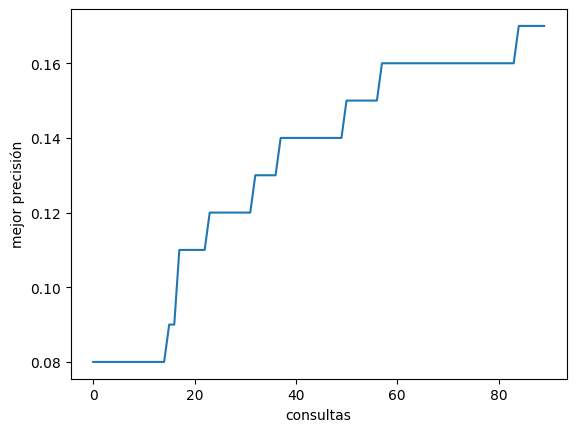

In [10]:
tabla = pd.DataFrame(REGISTRO)
display(tabla)

nuevas = int((tabla["segundos"] > 5).sum())
print(f"configuraciones evaluadas: {len(tabla)} de {len(CONFIGS) * len(TEMPERATURAS)} posibles "
      f"({len(tabla) / len(CONFIGS):.2%} del espacio a temperatura 0.0)")
print(f"generadas en esta sesión: {nuevas}  ·  recuperadas de la caché: {len(tabla) - nuevas}")
print(f"tiempo de GPU en esta sesión: {tabla['segundos'].sum() / 3600:.1f} h")

curva(historial)

**Nota sobre la ejecución.** Esta salida es la de la **reanudación**: la primera sesión (fase 1 y 84 de las 88 configuraciones de la fase 2) se cortó al agotarse la cuota de GPU de Colab, y el notebook se volvió a ejecutar desde el inicio con otra cuenta, copiando `oraculo_cache.json` a su Drive. Por eso 84 configuraciones aparecen en 0 s (recuperadas de la caché) y solo 6 se generaron aquí. Los resultados son idénticos porque el recorrido es determinista. Tiempo total de GPU de la búsqueda: ≈ 4.7 h.


### Fallos de la configuración elegida

Qué familias siguen tumbando instancias con la configuración final, y algunas salidas de ejemplo.

In [11]:
r = RESULTADOS[clave(mejor[1])]
print(f"falla {len(r.trazas)} de {r.n} instancias; por familia:")
for fam, k in fallos_por_familia(r).most_common():
    print(f"  {k:3d}  {fam}")

for t in r.trazas[:3]:
    print("-" * 60)
    print("violó:", t["violo"])
    print(t["salida"][:300])

falla 83 de 100 instancias; por familia:
   15  detectable_format
   14  keywords
   12  copy
    8  last_word
    7  punctuation
    5  length_constraints
    5  first_word
    5  new
    5  change_case
    2  paragraphs
    2  language
    1  letters
    1  startend
    1  combination
------------------------------------------------------------
violó: punctuation:punctuation_dot
Happy to help!

PROJECT ANALYSIS REPORT

The function analyzes the completion percentages of a list of projects and calculates the average completion, high priority average completion, and count of completed projects. For the given example, the average completion is 80, which is calculated by taking
------------------------------------------------------------
violó: punctuation:punctuation_dot
"Happy to help!

THE Mysterious and enigmatic stranger, known for sharing their most heart-wrenching and passionate love story, traveled from city to city, leaving behind tales of romance that captivated everyone. IN EA

## 10 · Validación final

`oraculo.validar` mide la configuración ya elegida sobre las **87 instancias de validación**, que no se usaron al buscar (misma distribución que búsqueda). Mide si la configuración generaliza a **instancias nuevas**; no a familias de restricciones nuevas, que es lo que tiene el test privado del profesor. **No se usa para elegir entre candidatas.**

In [12]:
r_val = oraculo.validar(mejor[1])

print()
print("búsqueda (mejor):", f"{mejor[0]:.1%}  ({len(INSTANCIAS)} inst)")
print("validación:      ", f"{r_val.precision:.1%}  ({r_val.n} inst)")

validando:   0%|          | 0/87 [00:00<?, ?inst/s]

validación: 17.2%  (87 inst)
    6  last_word:last_word_sent
    5  keywords:no_adjacent_consecutive
    5  copy:repeat_phrase
    4  first_word:first_word_sent
    4  punctuation:punctuation_dot
    3  punctuation:no_comma
    3  letters:letter_counting
    3  detectable_format:bigram_wrapping

búsqueda (mejor): 17.0%  (100 inst)
validación:       17.2%  (87 inst)


**Interpretación:** la configuración elegida acierta **17.2 %** en validación (15 de 87) frente a **17.0 %** en búsqueda (17 de 100). La diferencia, 0.2 puntos, es mucho menor que el ruido de muestreo: con $n = 87$ y $p \approx 0.17$ el error estándar es $\sqrt{p(1-p)/n} \approx 4$ puntos, así que cualquier diferencia de menos de ~8 puntos es compatible con el azar. Como la configuración se eligió como la mejor de 90 sobre búsqueda, cabía esperar que validación diera algo menos (sesgo del ganador); no ocurrió, de modo que **no hay señal de sobreajuste al lote de búsqueda**. Las restricciones que más fallan en validación (`last_word`, `keywords`, `copy`, `first_word`, `punctuation`) son las mismas familias que en búsqueda.

Límites: validación tiene la misma distribución que búsqueda; el test privado trae familias de restricciones nuevas, así que la precisión allí puede ser distinta. `validar` se llamó una sola vez, sobre la configuración ya elegida.


## 11 · Entrega

In [13]:
import shutil

from ayudas import entrega
from google.colab import files

GRUPO = "ADAG1"
SEMANA = 2

entrega(grupo=GRUPO, config=mejor[1], semana=SEMANA)
shutil.copy("entrega.json", f"{CARPETA}/entrega.json")
pd.DataFrame(REGISTRO).to_csv("registro_evaluaciones.csv", index=False)

files.download("entrega.json")
files.download("registro_evaluaciones.csv")

{
 "grupo": "ADAG1",
 "config": {
  "rol": 0,
  "estrategia": 5,
  "formato": 0,
  "estilo": 2,
  "cierre": 3,
  "temperatura": 0.0
 },
 "semana": 2
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>